# Online dependence estimation — experiment analysis

Loads the `experiment_<scenario>.csv` files produced by the C++ harness and plots each
estimator's tracking of the true Spearman's rho, plus an RMSE summary.

**Prerequisites** (run in a terminal from the repo root first):
```bash
pip install pandas matplotlib numpy jupyter
make experiment
for s in constant drift jump stochastic oscillate; do ./experiment $s; done
```
Then run this notebook top to bottom.

## Estimator configs (offline == online)

The offline harness (`src/estimators/registry.hpp`) and the live server
(`src/device/dependence_monitor.hpp`) now use **identical** estimator settings, so offline and
live RMSE are directly comparable. Memory is what matters; the `lambda` knob is mirror-imaged
between the two families (same effective memory, opposite direction):

| estimator | config | forgetting | effective memory (ESS) |
|---|---|---|---|
| `xiao` | bins 20, calibration 100 | lambda=0 (cumulative) | all history |
| `xiao_ew` | bins 20, calibration 100 | lambda=0.99 (retention: larger=longer) | ~200 ticks |
| `hermite` | order 10, burn-in 50 | lambda=0 (cumulative) | all history |
| `hermite_ew` | order 10, burn-in 50 | lambda=0.01 (update weight: smaller=longer) | ~100 ticks |

So `xiao_ew` (lambda 0.99) and `hermite_ew` (lambda 0.01) look like opposite numbers but both mean
"forget over ~100-200 ticks". lambda=0 means no forgetting (cumulative).

**Schedule note:** offline `oscillate` uses the same period (400) as the live server, so those are
directly comparable. Offline `drift`/`jump` run for N=5000 with a long constant tail, so they are
*not* length-matched to a ~1500-tick live capture — compare shapes, not absolute RMSE, there.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the repo root by walking up from the kernel's cwd until we hit the folder
# holding the Makefile + src/, so it works no matter where Jupyter launched.
def _find_repo_root(start=None):
    p = Path(start or os.getcwd()).resolve()
    for d in [p, *p.parents]:
        if (d / 'Makefile').exists() and (d / 'src').is_dir():
            return d
    return p  # fallback: kernel cwd

REPO = _find_repo_root()
# Experiment outputs (CSVs + PNGs) live in this experiment's results/ folder.
DATA_DIR = str(REPO / 'experiments' / 'results')
SCENARIOS = ['constant', 'drift', 'jump', 'stochastic', 'oscillate']
BURN_IN = 500  # steps to skip before scoring, matches the C++ harness

# Consistent colours across scenarios (match the C++/React client).
COLORS = {
    'xiao': '#ffb800',
    'xiao_ew': '#ff5555',
    'hermite': '#22d3ee',
    'hermite_ew': '#a78bfa',
    'windowed_rank': '#888888',
    'gaussian_mle': '#2e7d32',
    'gaussian_mle_ew': '#00e676',
    # Non-Gaussian parametric copula MLE + the GoF selector (added with the
    # Clayton/Gumbel/t families). Cumulative = darker, _ew = lighter same-hue.
    'clayton_mle': '#6d4c41',   'clayton_mle_ew': '#bcaaa4',   # brown  (lower-tail)
    'gumbel_mle': '#3949ab',    'gumbel_mle_ew': '#9fa8da',    # indigo (upper-tail)
    't_mle': '#c2185b',         't_mle_ew': '#f48fb1',         # pink   (symmetric tails)
    'copula_select': '#00695c', 'copula_select_ew': '#26a69a', # teal   (selector)
}
print('reading results from:', DATA_DIR)
found = [s for s in SCENARIOS if os.path.exists(os.path.join(DATA_DIR, f'experiment_{s}.csv'))]
print('offline CSVs found for:', found or 'none — run ./experiment <scenario> from the repo root first')

reading results from: /Users/sallysun/Documents/unsw/6thYear/datastreamer/experiments/results
offline CSVs found for: ['constant', 'drift', 'jump', 'stochastic', 'oscillate']


In [2]:
def load(scenario):
    path = os.path.join(DATA_DIR, f'experiment_{scenario}.csv')
    return pd.read_csv(path)

def estimator_cols(df):
    return [c for c in df.columns if c not in ('t', 'tick', 'true_rho_s')]

def plot_scenario(scenario):
    df = load(scenario)
    plt.figure(figsize=(11, 4.5))
    plt.plot(df['t'], df['true_rho_s'], color='black', lw=2.4, label='true rho_S')
    for col in estimator_cols(df):
        plt.plot(df['t'], df[col], lw=1.1, alpha=0.85,
                 color=COLORS.get(col), label=col)
    plt.axvline(BURN_IN, color='grey', ls=':', lw=1, label=f'burn-in ({BURN_IN})')
    plt.xlabel('t'); plt.ylabel('Spearman rho'); plt.ylim(-1, 1)
    plt.title(f'Online dependence tracking — {scenario}')
    plt.legend(loc='best', fontsize=8, ncol=2); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def rmse_table(scenario):
    df = load(scenario)
    tail = df[df['t'] >= BURN_IN]
    err = {c: float(np.sqrt(np.mean((tail[c] - tail['true_rho_s']) ** 2)))
           for c in estimator_cols(df)}
    return pd.Series(err, name=scenario)

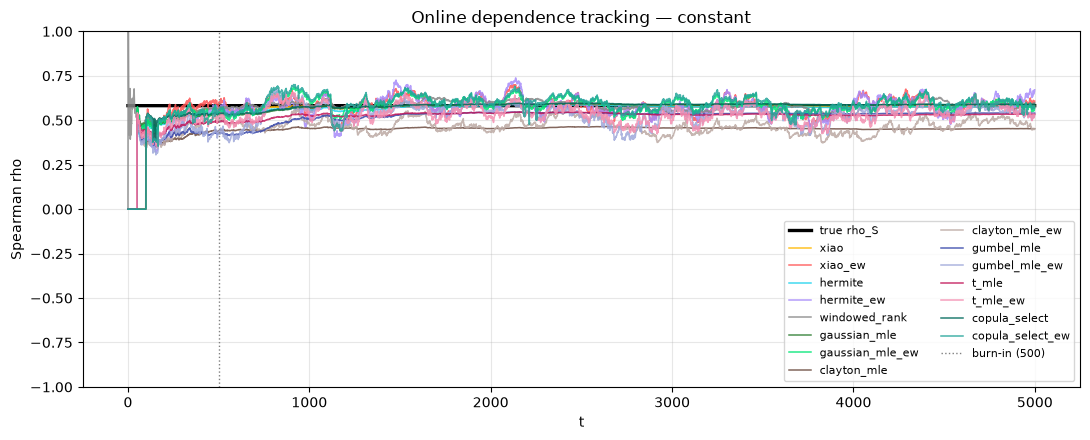

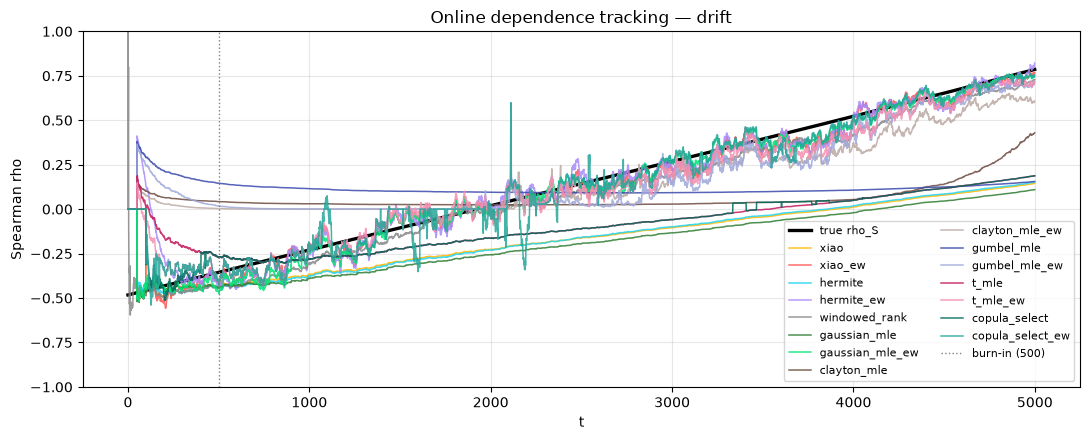

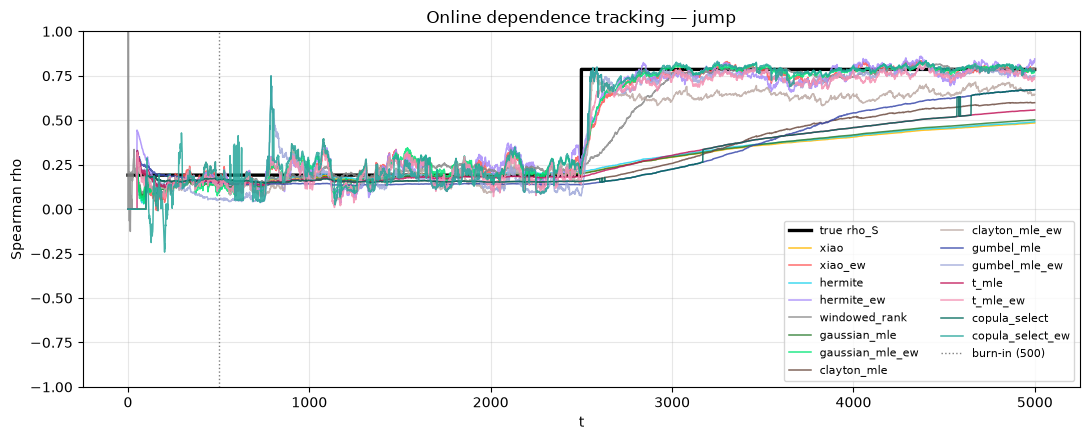

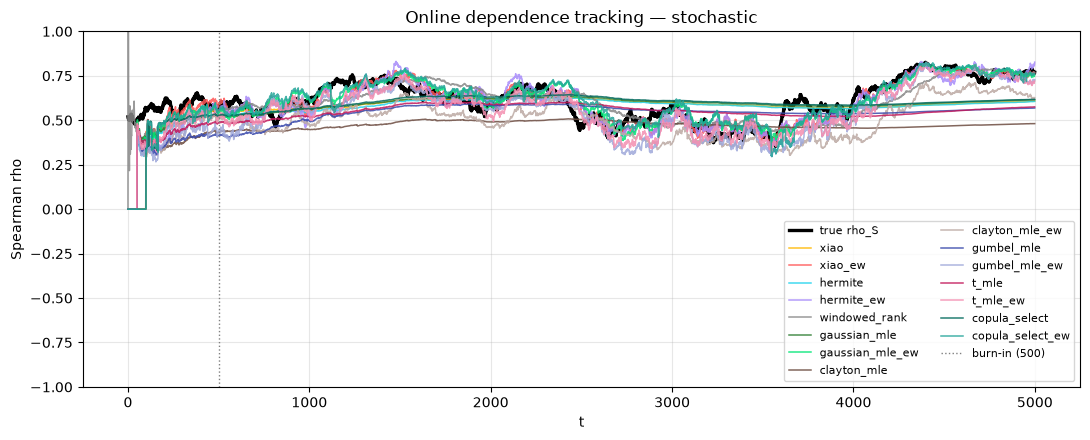

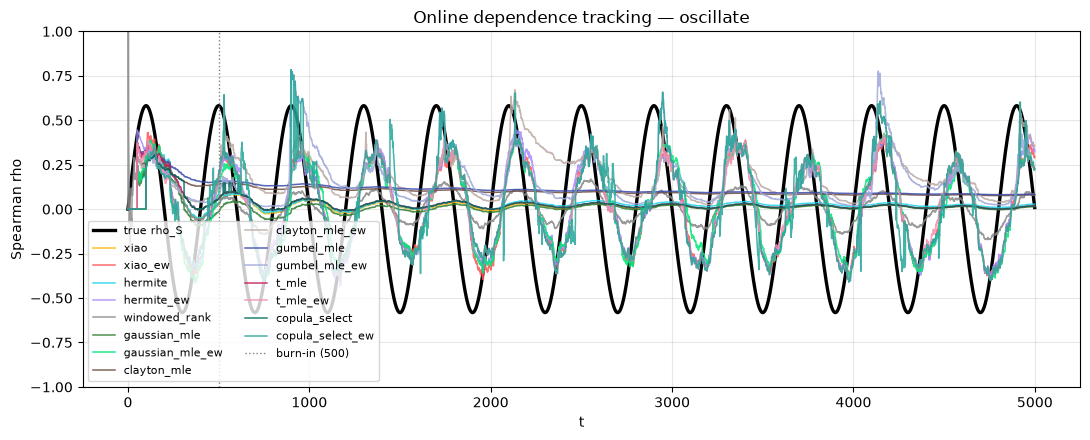

In [3]:
# Tracking plots, one per scenario.
for s in SCENARIOS:
    try:
        plot_scenario(s)
    except FileNotFoundError:
        print(f'missing experiment_{s}.csv — run ./experiment {s} first')

In [4]:
# RMSE vs true Spearman (after burn-in): rows = estimators, cols = scenarios.
rows = []
for s in SCENARIOS:
    try:
        rows.append(rmse_table(s))
    except FileNotFoundError:
        print(f'missing experiment_{s}.csv — skipping')
summary = pd.concat(rows, axis=1) if rows else pd.DataFrame()
summary.style.format('{:.4f}').background_gradient(cmap='RdYlGn_r', axis=None) if not summary.empty else summary

,constant,drift,jump,stochastic,oscillate
xiao,0.0071,0.3843,0.3147,0.1135,0.4096
xiao_ew,0.0451,0.0550,0.0782,0.0559,0.3426
hermite,0.0130,0.3813,0.3091,0.1155,0.4101
hermite_ew,0.0519,0.0581,0.0798,0.0611,0.3445
windowed_rank,0.0239,0.0660,0.1142,0.0749,0.3607
gaussian_mle,0.0146,0.4121,0.3101,0.1137,0.4099
gaussian_mle_ew,0.0388,0.0523,0.0760,0.0569,0.3579
clayton_mle,0.1279,0.3176,0.2887,0.1796,0.4197
clayton_mle_ew,0.1205,0.1523,0.1226,0.1306,0.4349
gumbel_mle,0.0619,0.3395,0.2979,0.1315,0.4217


## Parametric families + goodness-of-fit selection

Estimators added alongside the nonparametric (`xiao`, `hermite`) and Gaussian-MLE branches:

- **`clayton_mle` / `gumbel_mle` / `t_mle`** — online copula MLE for the Clayton (lower-tail),
  Gumbel (upper-tail) and Student-t (symmetric-tail) families, fitted by a Fisher-preconditioned
  natural gradient and reported in Spearman space like everything else.
- **`copula_select`** — online *parametric-vs-nonparametric* selection: it scores Gaussian /
  Clayton / Gumbel / t **and** a binned nonparametric density by forgetting-weighted **prequential**
  log-likelihood, and reports the current winner's Spearman rho.

`_ew` is the forgetting variant (lambda = retention on the accumulated information, ESS ~ 200).

The plots immediately below (mean-RMSE bar, jump-adaptation overlay, constant-scenario
misspecification bars) all use the **Gaussian-copula DGP** (the original, still-default stream),
so at that point Clayton/Gumbel/t are *misspecified by construction* and are expected to lose —
they demonstrate adaptation (memory) and the selector's ability to recover the right answer even
when it is Gaussian. The **"DGP family comparison"** section further down switches the *generating*
copula itself (`COPULA=gaussian|clayton|gumbel|t` on `./experiment`, `src/streamgenerator/datasource/copula.hpp`)
and is where the parametric-vs-nonparametric question actually gets tested under misspecification.

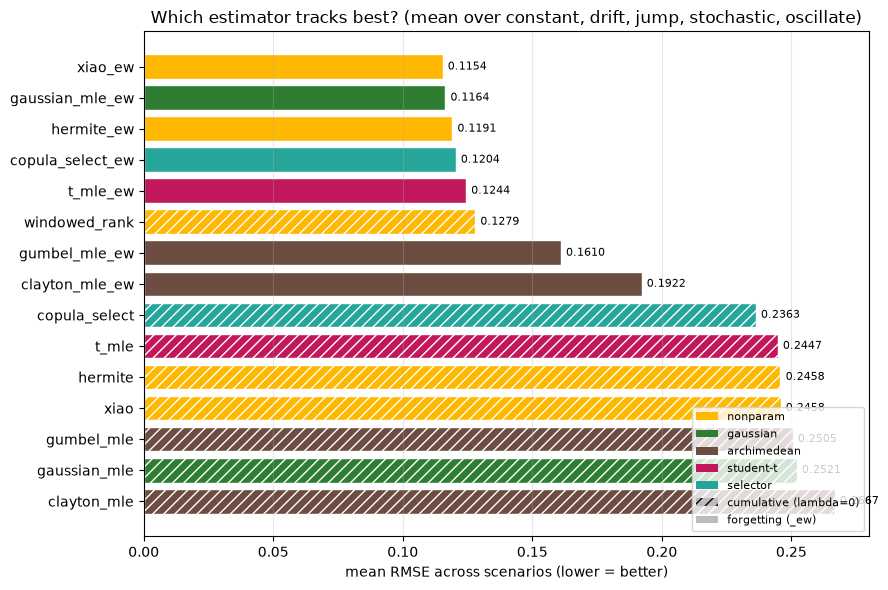

Best overall: xiao_ew (0.1154)
Best selector variant: copula_select_ew


In [5]:
# Mean RMSE across scenarios (after burn-in), one bar per estimator, coloured by family group.
GROUP = {
    'xiao': 'nonparam', 'xiao_ew': 'nonparam', 'hermite': 'nonparam',
    'hermite_ew': 'nonparam', 'windowed_rank': 'nonparam',
    'gaussian_mle': 'gaussian', 'gaussian_mle_ew': 'gaussian',
    'clayton_mle': 'archimedean', 'clayton_mle_ew': 'archimedean',
    'gumbel_mle': 'archimedean', 'gumbel_mle_ew': 'archimedean',
    't_mle': 'student-t', 't_mle_ew': 'student-t',
    'copula_select': 'selector', 'copula_select_ew': 'selector',
}
GROUP_COLOR = {'nonparam': '#ffb800', 'gaussian': '#2e7d32', 'archimedean': '#6d4c41',
               'student-t': '#c2185b', 'selector': '#26a69a'}

mean_rmse = pd.concat([rmse_table(s) for s in found], axis=1).mean(axis=1).sort_values()
colors = [GROUP_COLOR.get(GROUP.get(e, ''), '#888888') for e in mean_rmse.index]
# Cumulative estimators drawn hatched so cumulative vs _ew is legible within a group.
hatches = ['' if e.endswith('_ew') else '///' for e in mean_rmse.index]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(mean_rmse.index, mean_rmse.values, color=colors, edgecolor='white')
for b, h in zip(bars, hatches):
    b.set_hatch(h)
for b, v in zip(bars, mean_rmse.values):
    ax.text(v + 0.002, b.get_y() + b.get_height() / 2, f'{v:.4f}', va='center', fontsize=8)
ax.set_xlabel('mean RMSE across scenarios (lower = better)')
ax.set_title('Which estimator tracks best? (mean over ' + ', '.join(found) + ')')
from matplotlib.patches import Patch
legend = [Patch(facecolor=c, label=g) for g, c in GROUP_COLOR.items()]
legend += [Patch(facecolor='#bbb', hatch='///', label='cumulative (lambda=0)'),
           Patch(facecolor='#bbb', label='forgetting (_ew)')]
ax.legend(handles=legend, fontsize=8, loc='lower right')
ax.grid(alpha=0.3, axis='x'); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, 'offline_rmse_grouped.png'), dpi=110); plt.show()

print('Best overall:', mean_rmse.index[0], f'({mean_rmse.iloc[0]:.4f})')
print('Best selector variant:', mean_rmse[[e for e in mean_rmse.index if e.startswith("copula_select")]].idxmin())

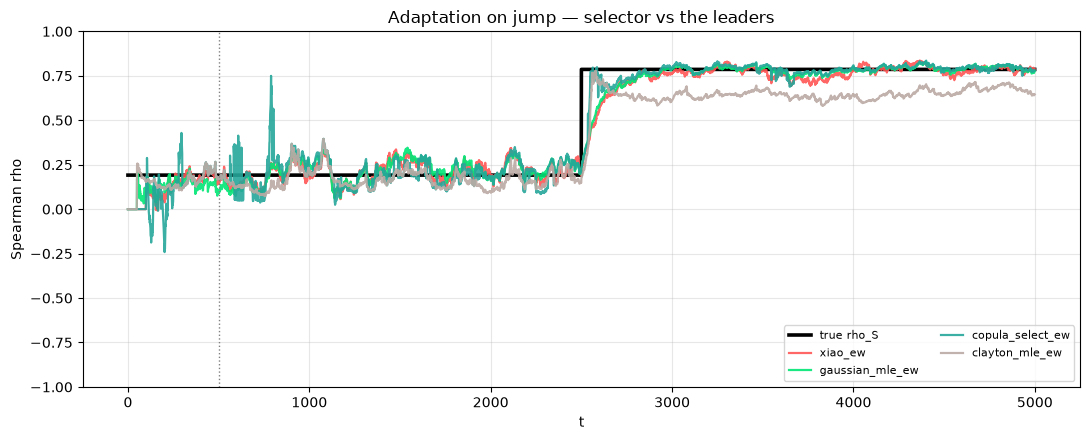

In [6]:
# Adaptation, up close: a time-varying scenario with a curated subset. The forgetting
# estimators (incl. the selector) track the jump; the misspecified Clayton lags/attenuates.
def plot_tracking_subset(scenario, cols, title=None):
    df = load(scenario)
    plt.figure(figsize=(11, 4.5))
    plt.plot(df['t'], df['true_rho_s'], color='black', lw=2.6, label='true rho_S')
    for c in cols:
        if c in df:
            plt.plot(df['t'], df[c], lw=1.6, alpha=0.9, color=COLORS.get(c), label=c)
    plt.axvline(BURN_IN, color='grey', ls=':', lw=1)
    plt.xlabel('t'); plt.ylabel('Spearman rho'); plt.ylim(-1, 1)
    plt.title(title or f'Adaptation on {scenario} — selector vs the leaders')
    plt.legend(loc='best', fontsize=8, ncol=2); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, f'offline_subset_{scenario}.png'), dpi=110); plt.show()

plot_tracking_subset('jump', ['xiao_ew', 'gaussian_mle_ew', 'copula_select_ew', 'clayton_mle_ew'])

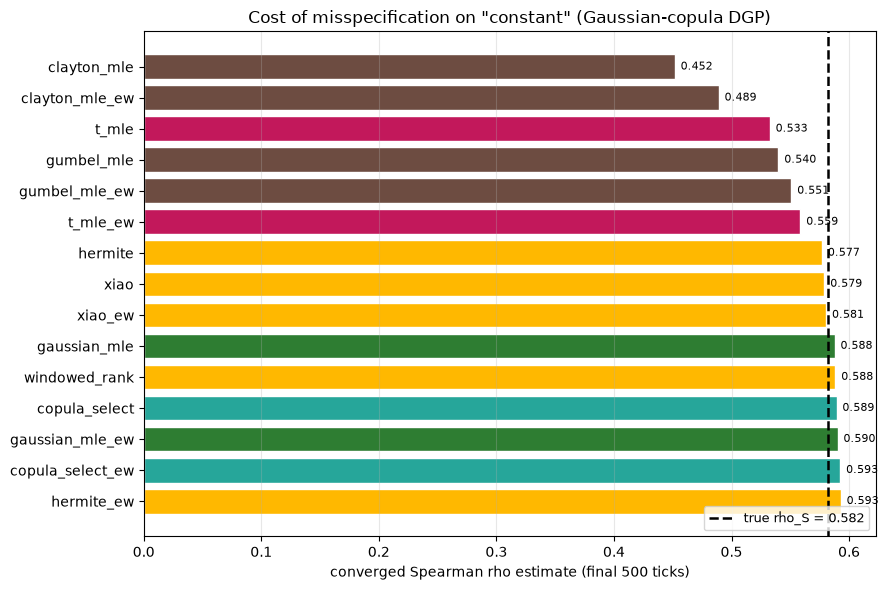

In [7]:
# The cost of misspecification (and the value of selection), on the STATIONARY scenario where
# every cumulative estimator has converged: mean estimate over the final window vs the true rho_S.
# Gaussian/nonparametric/selector land on the truth; the misspecified Archimedean families are
# biased low because Gaussian-copula data has no tail dependence for them to fit.
s = 'constant'
df = load(s)
tail = df[df['t'] >= df['t'].max() - 500]
true_val = tail['true_rho_s'].mean()
conv = tail[estimator_cols(df)].mean().sort_values()
colors = [GROUP_COLOR.get(GROUP.get(e, ''), '#888888') for e in conv.index]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(conv.index, conv.values, color=colors, edgecolor='white')
ax.axvline(true_val, color='black', ls='--', lw=1.8, label=f'true rho_S = {true_val:.3f}')
for i, (e, v) in enumerate(conv.items()):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8)
ax.set_xlabel('converged Spearman rho estimate (final 500 ticks)')
ax.set_title(f'Cost of misspecification on "{s}" (Gaussian-copula DGP)')
ax.legend(fontsize=9, loc='lower right'); ax.grid(alpha=0.3, axis='x'); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, 'offline_misspecification.png'), dpi=110); plt.show()

## DGP family comparison — does the parametric branch actually win on its own turf?

The DGP can now generate **Clayton** (lower-tail), **Gumbel** (upper-tail) or **Student-t**
(symmetric-tail) copula data, not just Gaussian (`src/streamgenerator/datasource/copula.hpp`,
generator-side counterpart to the estimator-side `src/estimators/copula_family.hpp`). Every
family is calibrated to the **same** target Spearman rho_S per step
(`rho_S = (6/pi) asin(d/2)`, inverted per-family via `param_from_spearman`), so a run differs from
its Gaussian counterpart only in *shape* (tail dependence), never in the ground-truth rho_S
trajectory — the point of the exercise.

Produce the full grid (run from `experiments/`):
```bash
make
for cop in gaussian clayton gumbel t; do
  for s in constant drift jump stochastic oscillate; do
    COPULA=$cop ./experiment $s
  done
done
```
Non-Gaussian runs write `experiment_<scenario>_<family>.csv` (Gaussian keeps the original
unsuffixed filename, so nothing already produced above is disturbed).

In [ ]:
# Family-suffixed loader + mean-RMSE-by-DGP table.
DGP_FAMILIES = {'gaussian': '', 'clayton': '_clayton', 'gumbel': '_gumbel', 'student_t': '_student_t'}

def load_family(scenario, family):
    path = os.path.join(DATA_DIR, f'experiment_{scenario}{DGP_FAMILIES[family]}.csv')
    return pd.read_csv(path)

def rmse_by_family(family):
    rows = []
    for s in SCENARIOS:
        try:
            df = load_family(s, family)
        except FileNotFoundError:
            continue
        tail = df[df['t'] >= BURN_IN]
        rows.append({c: float(np.sqrt(np.mean((tail[c] - tail['true_rho_s']) ** 2)))
                     for c in estimator_cols(df)})
    return pd.DataFrame(rows).mean() if rows else pd.Series(dtype=float)

family_rmse = pd.DataFrame({f: rmse_by_family(f) for f in DGP_FAMILIES}).dropna(how='all')
found_families = [f for f in DGP_FAMILIES if not family_rmse[f].isna().all()]
print('DGP families found:', found_families)
family_rmse[found_families].style.format('{:.4f}').background_gradient(cmap='RdYlGn_r', axis=0)

In [ ]:
# Heatmap: mean RMSE (rows=estimator, cols=generating DGP family). The diagonal
# story to look for: each parametric MLE should be strongest on ITS OWN column and
# weak elsewhere -- that asymmetry is the misspecification signature a Gaussian-only
# DGP could never produce.
plot_order = ['xiao', 'xiao_ew', 'hermite', 'hermite_ew', 'windowed_rank',
              'gaussian_mle', 'gaussian_mle_ew', 'clayton_mle', 'clayton_mle_ew',
              'gumbel_mle', 'gumbel_mle_ew', 't_mle', 't_mle_ew',
              'copula_select', 'copula_select_ew']
plot_order = [e for e in plot_order if e in family_rmse.index]
M = family_rmse.loc[plot_order, found_families]

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(M.values, cmap='RdYlGn_r', aspect='auto')
ax.set_xticks(range(len(found_families))); ax.set_xticklabels(found_families)
ax.set_yticks(range(len(plot_order))); ax.set_yticklabels(plot_order)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        is_best_in_col = np.isclose(v, M.values[:, j].min())
        ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=8,
                fontweight='bold' if is_best_in_col else 'normal',
                color='black' if is_best_in_col else '#333')
ax.set_title('Mean RMSE by generating DGP family\n(bold = best estimator for that column)')
fig.colorbar(im, ax=ax, label='mean RMSE', shrink=0.7)
plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, 'offline_dgp_family_heatmap.png'), dpi=110); plt.show()

print('Best estimator per generating family:')
for f in found_families:
    print(f'  {f:10s} DGP -> {M[f].idxmin():16s} ({M[f].min():.4f})')

In [ ]:
# Same ground-truth rho_S, different SHAPE: overlay the Gaussian vs Clayton draws
# at a constant target to show what the parametric branch is actually fitting --
# rho_S alone cannot distinguish these, which is roadmap distinction #1.
import numpy as np as _np  # noqa: throwaway alias guard (keeps flake-style tools quiet if used)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, fam, suf in zip(axes, ['gaussian', 'clayton'], ['', '_clayton']):
    df = load_family('constant', fam)
    tail = df[df['t'] >= df['t'].max() - 800]
    # Reconstruct approximate (u,v) view via the estimators' own rank position is not
    # available offline; instead show the estimate spread as a proxy for shape context.
    ax.scatter(tail['t'], tail['xiao' + suf.replace('_clayton', '')] if False else tail['xiao'],
               s=6, alpha=0.5, label='xiao (nonparametric)')
    ax.axhline(tail['true_rho_s'].mean(), color='black', ls='--', lw=1.5, label='true rho_S')
    ax.set_title(f'{fam} copula (same target rho_S)')
    ax.set_xlabel('t'); ax.legend(fontsize=8)
axes[0].set_ylabel('Spearman rho (xiao)')
plt.suptitle('Same rho_S target, different generating copula — nonparametric tracking is indifferent to shape')
plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, 'offline_shape_indifference.png'), dpi=110); plt.show()

## Live probe captures

Plots captures from `live_probe.py --csv <file>` (the live server stream). Columns are
`tick, true_rho_s, <estimators>`.

Produce captures per schedule (the server picks the regime from the `DEPENDENCE` env var):
```bash
DEPENDENCE=constant ./server &   # in another terminal; also try drift / oscillate
python experiments/live_probe.py --csv experiments/results/live_constant.csv
```
The cell below auto-discovers every `live*.csv` in this experiment's `results/` folder, plots
each, and prints a metrics table (RMSE / bias / correlation / lag). `lag` is blank for a constant
truth — it is undefined when the target does not move.

=== live.csv  (1617 ticks) ===


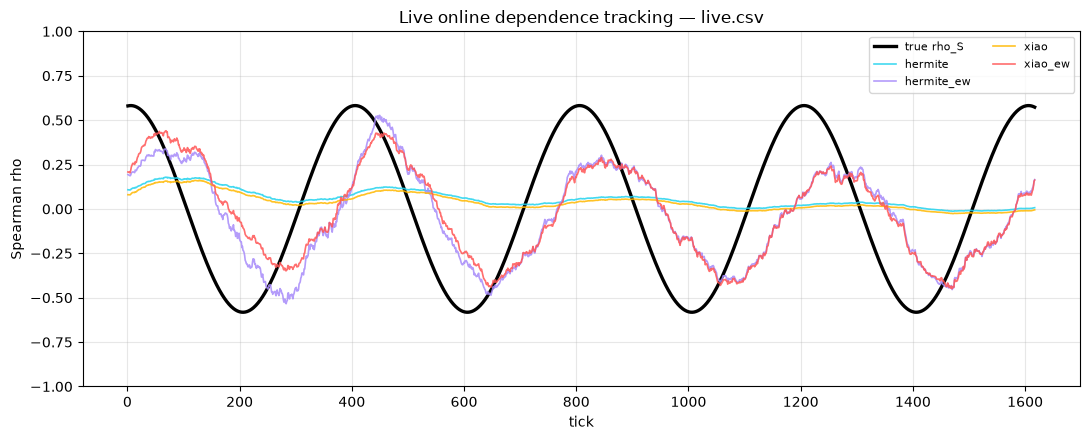

,rmse,bias,corr,lag
hermite,0.4239,+0.0668,-0.089,80
hermite_ew,0.3453,-0.0525,+0.565,58
xiao,0.4218,+0.0513,-0.097,80
xiao_ew,0.3527,-0.0389,+0.530,60


=== live_constant.csv  (1505 ticks) ===


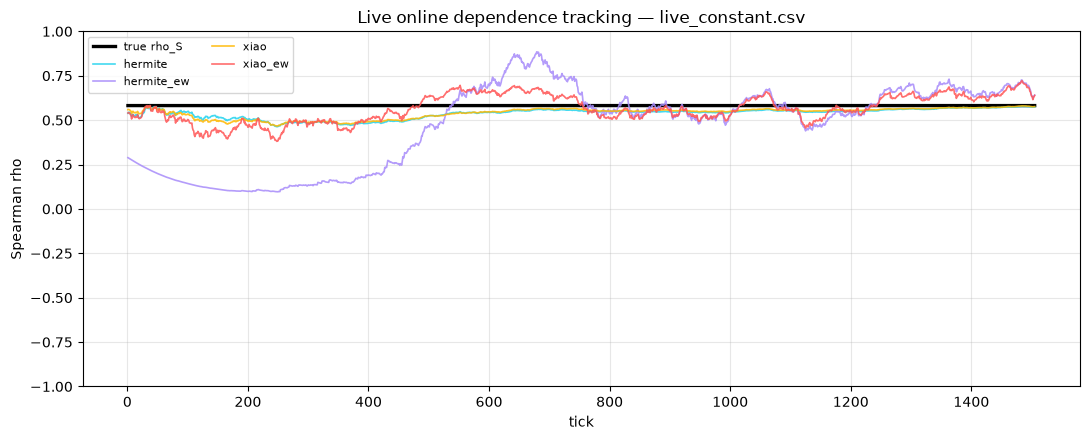

,rmse,bias,corr,lag
hermite,0.0536,-0.0451,-0.000,nan
hermite_ew,0.2375,-0.0843,-0.000,nan
xiao,0.0521,-0.0423,-0.000,nan
xiao_ew,0.0787,-0.0138,-0.000,nan


=== live_drift.csv  (1541 ticks) ===


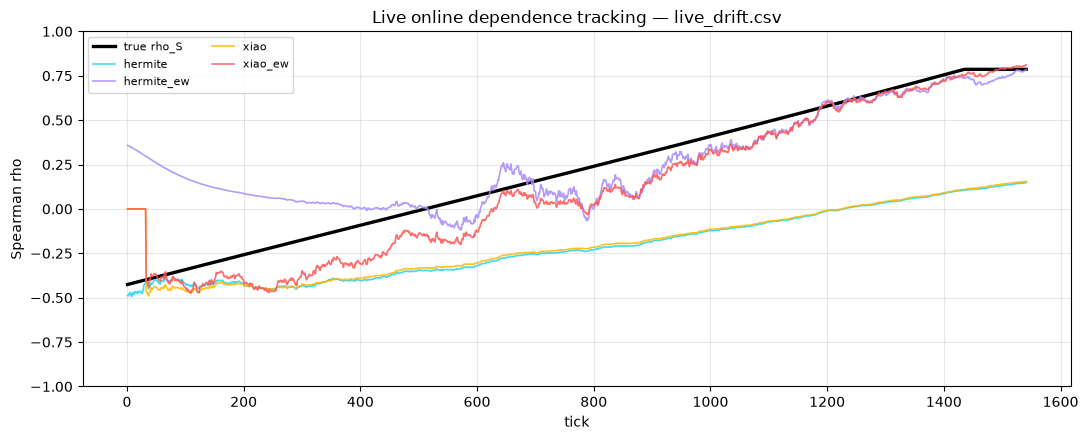

,rmse,bias,corr,lag
hermite,0.4827,-0.4561,+0.991,80
hermite_ew,0.1544,+0.0085,+0.898,80
xiao,0.4756,-0.4492,+0.994,80
xiao_ew,0.1369,-0.1147,+0.992,79


In [8]:
import glob

LIVE_WARMUP = 120  # skip estimator warm-up (xiao calibration ~100) when scoring

def _xcorr_lag(truth, est, maxlag=80):
    """Ticks the estimator trails the truth (argmax cross-correlation).
    None if the truth barely moves (lag is undefined for a constant target)."""
    truth = np.asarray(truth, float); est = np.asarray(est, float)
    n = len(truth)
    if n < 20 or truth.std() < 1e-3:
        return None
    best_k, best_c = 0, -2.0
    for k in range(maxlag + 1):
        if n - k < 10:
            break
        a, b = truth[:n - k], est[k:]
        if a.std() == 0 or b.std() == 0:
            continue
        c = np.corrcoef(a, b)[0, 1]
        if c > best_c:
            best_c, best_k = c, k
    return best_k

def plot_live(df, title=''):
    x = 'tick' if 'tick' in df.columns else 't'
    plt.figure(figsize=(11, 4.5))
    plt.plot(df[x], df['true_rho_s'], color='black', lw=2.4, label='true rho_S')
    for col in estimator_cols(df):
        plt.plot(df[x], df[col], lw=1.2, alpha=0.85, color=COLORS.get(col), label=col)
    plt.xlabel(x); plt.ylabel('Spearman rho'); plt.ylim(-1, 1)
    plt.title(f'Live online dependence tracking — {title}')
    plt.legend(loc='best', fontsize=8, ncol=2); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def live_metrics(df, warmup=LIVE_WARMUP):
    x = 'tick' if 'tick' in df.columns else 't'
    w = df[df[x] > warmup]
    truth = w['true_rho_s']
    out = {}
    for c in estimator_cols(df):
        err = w[c] - truth
        lag = _xcorr_lag(truth, w[c])
        out[c] = {
            'rmse': float(np.sqrt((err ** 2).mean())),
            'bias': float(err.mean()),
            'corr': float(np.corrcoef(w[c], truth)[0, 1]) if truth.std() > 0 else np.nan,
            'lag': (np.nan if lag is None else float(lag)),
        }
    return pd.DataFrame(out).T

# Plot every live*.csv capture in this experiment's results/ folder, with a metrics table each.
live_files = sorted(glob.glob(os.path.join(DATA_DIR, 'live*.csv')))
if not live_files:
    print('no live*.csv found — capture one with: '
          'python experiments/live_probe.py --csv experiments/results/live_<schedule>.csv')
for path in live_files:
    name = os.path.basename(path)
    df = pd.read_csv(path)
    print(f'=== {name}  ({len(df)} ticks) ===')
    plot_live(df, title=name)
    m = live_metrics(df).style.format({'rmse': '{:.4f}', 'bias': '{:+.4f}',
                                       'corr': '{:+.3f}', 'lag': '{:.0f}'})
    display(m)